# 04 · Team clustering (Extra Mile)

**Why:** on the tactical map every rider should get his team's colour, without anyone telling the app which team is which. This is the brief's Extra Mile track *Tactical analytics*: dynamic team colour clustering with HSV and K-Means on the jerseys.

1. **Player boxes** for every frame, from `models/detections.csv`.
2. **Shirt colours** of each box, in HSV.
3. **K-Means** with two clusters: two tries.
4. **Checks:** do the teams split 2 v 2, and do the crops look right?
5. **Hand-off:** `models/teams.csv`, one team per player box, for the app.

**Run:** open in VS Code or Jupyter with the project's Python and *Run All*. Needs only the repo (the video and `models/detections.csv` are in git); reading all 1,170 frames takes about a minute. Figures are saved to `reports/team_clustering/` (not in git, because they show video frames).

**Author:** Ryan Omondi (error analysis and team clustering, role C)

> **GenAI:** I used AI to write the code and a first draft of the text from our plan (steps 1–5 above), then had it go back over the whole notebook against the brief. Caught and fixed on the way:
> - **Colours set by hand:** an earlier version used fixed kit colours. We dropped it because the Extra Mile asks for colours learned from the clip, and kept the histogram version (92% of frames split 2 v 2).
> - **Blue drawn orange:** OpenCV stores colours as BGR, not RGB, so the blue team came out orange in the figures.
> - **Claim without proof:** the first drafts blamed the detector, then the shirt colour, for the frames that don't split 2 v 2. Counting duplicates (15 of 71) and looking at the other 56 by eye showed it is both: 29 are a blue rider by the dark left goal put in the white team, the rest are looser double boxes and the referee inside a player box (§4b).
> - **Median colour:** the first draft said try 1 fails because both teams' median looks the same beige. Checking showed the two medians do differ, so the text now only says the median is a blend, not the shirt colour.

## Settings
All paths and numbers used below are set here. Colours are in OpenCV's HSV: hue 0–180 (half of the usual 0–360 degrees), saturation and value (brightness) 0–255.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from ultralytics.utils.metrics import box_iou

ROOT = Path.cwd().parent                        # this notebook lives in notebooks/
VIDEO = ROOT / "data/cycle-ball.mp4"            # 1,170 frames
DETECTIONS = ROOT / "models/detections.csv"     # boxes of the fine-tuned model for every frame (notebook 02 §7)
OUTPUT = ROOT / "models/teams.csv"              # one team per player box, for the app
REPORTS_DIR = ROOT / "reports/team_clustering"  # figures for the report (not in git: they show video frames)
XY = ["x1", "y1", "x2", "y2"]

# The shirt: from 10% to 50% of the box height (below the head, above the shorts), without 20% on each side.
SHIRT_TOP, SHIRT_BOTTOM, SHIRT_SIDE = 0.10, 0.50, 0.20
DARK_V = 40                 # darker than this: shadow, no usable colour
WHITE_S, WHITE_V = 60, 130  # white: low saturation and bright (loose, because the arena light makes white look yellowish)
HUE_BINS = 12               # hue histogram with 12 bins of 30 degrees
BLUE_BINS = slice(6, 9)     # bins 6-8 = 180-270 degrees, used only to name the clusters
TEAM_COLOURS = {"blue": (255, 120, 40), "white": (255, 255, 255)}   # BGR, for drawing
SEED = 0                    # K-Means starts from random centres; a fixed seed gives the same result every run

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Player boxes

Cycle ball is 2 v 2, so a perfect detector gives 4 player boxes per frame. A *duplicate* is two player boxes that overlap at IoU ≥ 0.5: two boxes on one rider.

In [2]:
def has_duplicate(boxes):
    overlap = box_iou(torch.tensor(boxes), torch.tensor(boxes)).numpy()
    return bool((np.triu(overlap, 1) >= 0.5).any())


players = pd.read_csv(DETECTIONS).query("`class` == 'player'").reset_index(drop=True)
counts = players.groupby("frame").size()
duplicates = players.groupby("frame")[XY].apply(lambda boxes: has_duplicate(boxes.to_numpy(float)))
print(f"{len(players)} player boxes in {len(counts)} frames")
pd.DataFrame({"frames": counts.value_counts(), "with a duplicate": duplicates.groupby(counts).sum()}).rename_axis("boxes per frame")

4669 player boxes in 1170 frames


,frames,with a duplicate
boxes per frame,,
3,175,0
4,858,42
5,118,107
6,13,13
7,4,4
8,2,2


**Findings:** 858 of the 1,170 frames have exactly 4 player boxes. In 175 frames a rider is missed. Of the 137 frames with 5 or more boxes, 126 contain a duplicate, so in almost all of them the extra box is a second box on a rider, not a fifth person.

## 2. Shirt colours

One pass over the video. For each player box we cut out the shirt and describe it in two ways:

- **Median colour:** the median hue, saturation and value of the shirt pixels.
- **Colour histogram:** the share of shirt pixels in each of the 12 hue bins, plus a share for white and one for dark. Nothing in it is specific to our teams, so it works for any two kits.

In [3]:
def shirt_colours(hsv, box):
    """Median HSV and colour histogram of the shirt part of one player box."""
    x1, y1, x2, y2 = box
    w, h = x2 - x1, y2 - y1
    pixels = hsv[int(y1 + SHIRT_TOP * h):int(y1 + SHIRT_BOTTOM * h), int(x1 + SHIRT_SIDE * w):int(x2 - SHIRT_SIDE * w)].reshape(-1, 3).astype(int)
    hue, sat, val = pixels.T
    dark = val < DARK_V
    white = ~dark & (sat < WHITE_S) & (val > WHITE_V)
    hues = np.bincount(hue[~dark & ~white] * HUE_BINS // 180, minlength=HUE_BINS)
    return np.median(pixels, axis=0), np.r_[hues, white.sum(), dark.sum()] / len(pixels)


median_colour, histogram = np.zeros((len(players), 3)), np.zeros((len(players), HUE_BINS + 2))
video = cv2.VideoCapture(str(VIDEO))
for frame in range(1, len(counts) + 1):         # frame numbers start at 1, like detections.csv
    ok, image = video.read()
    assert ok, f"could not read frame {frame}"
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    for i, box in players.loc[players.frame == frame, XY].iterrows():
        median_colour[i], histogram[i] = shirt_colours(hsv, box.to_numpy())

shirt = pd.DataFrame({"blue": histogram[:, BLUE_BINS].sum(1), "orange-yellow": histogram[:, 1:3].sum(1),
                      "white": histogram[:, HUE_BINS], "dark": histogram[:, HUE_BINS + 1]})
shirt.mean().round(3)

blue             0.119
orange-yellow    0.363
white            0.070
dark             0.284
dtype: float64

**Findings:** an average shirt crop is 28% dark (shadows; the blue team's crops are darker, see §4) and 36% orange-yellow (hue 30–90 degrees): the wooden floor and skin, which get into the crop between the arms and around the body, and the white kit, which looks warm under the arena lights. Blue is 12%, white 7%.

## 3. K-Means: two tries

K-Means with two clusters puts every box in the group whose centre is closest. It knows nothing about teams; it only finds the two most separate groups.

**How we check it without hand labels:** in a frame with exactly 4 player boxes, a correct clustering puts 2 in each team. The share of those frames that split **2 v 2** is our score. It is not perfect: a frame with a missed rider plus a duplicate box also has 4 boxes, and then 2 v 2 is impossible.

**Why the square root** of the histogram: most of a crop is one or two big colours (floor, skin, the main kit colour), while the colour that tells the teams apart can be a small share, like a blue sleeve seen from the side. The square root shrinks big shares more than small ones, so the small but telling ones still count.

In [4]:
def kmeans_two(features):
    """Two clusters with OpenCV's K-Means (no extra library); returns 0 or 1 per box."""
    cv2.setRNGSeed(SEED)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
    return cv2.kmeans(np.float32(features), 2, None, criteria, 10, cv2.KMEANS_PP_CENTERS)[1].ravel()


def split_2v2(cluster):
    per_frame = pd.Series(cluster).groupby(players.frame).agg(["size", "sum"])
    four = per_frame[per_frame["size"] == 4]
    return f"{(four['sum'] == 2).mean():.0%} of {len(four)} frames"


for name, features in {"1. median colour": median_colour / [180, 255, 255], "2. colour histogram (square root)": np.sqrt(histogram)}.items():
    print(f"{name:<34} split 2 v 2 in {split_2v2(kmeans_two(features))}")

1. median colour                   split 2 v 2 in 19% of 858 frames
2. colour histogram (square root)  split 2 v 2 in 92% of 858 frames


**Findings:**
- **Try 1, median colour, fails** (19%): a crop mixes shirt, skin, floor and shadow (section 2), so its median is a blend rather than the shirt colour, and the two groups K-Means finds are not the teams.
- **Try 2, the colour histogram, works** (92%): K-Means finds by itself that one group has more blue and dark, the other more white and warm colours.

**Conclusions:** we use try 2. The team colours are learned from the clip, so the same code works for a match with other kits.

## 4. Checks

K-Means only says cluster 0 or 1. To name the clusters, we compare their average shirt: the cluster with more blue is the blue team. Then 20 random boxes per team, with the shirt area in green and the border in the team colour.

,blue,orange-yellow,white,dark
team,,,,
blue,0.230,0.240,0.037,0.330
white,0.008,0.488,0.102,0.238


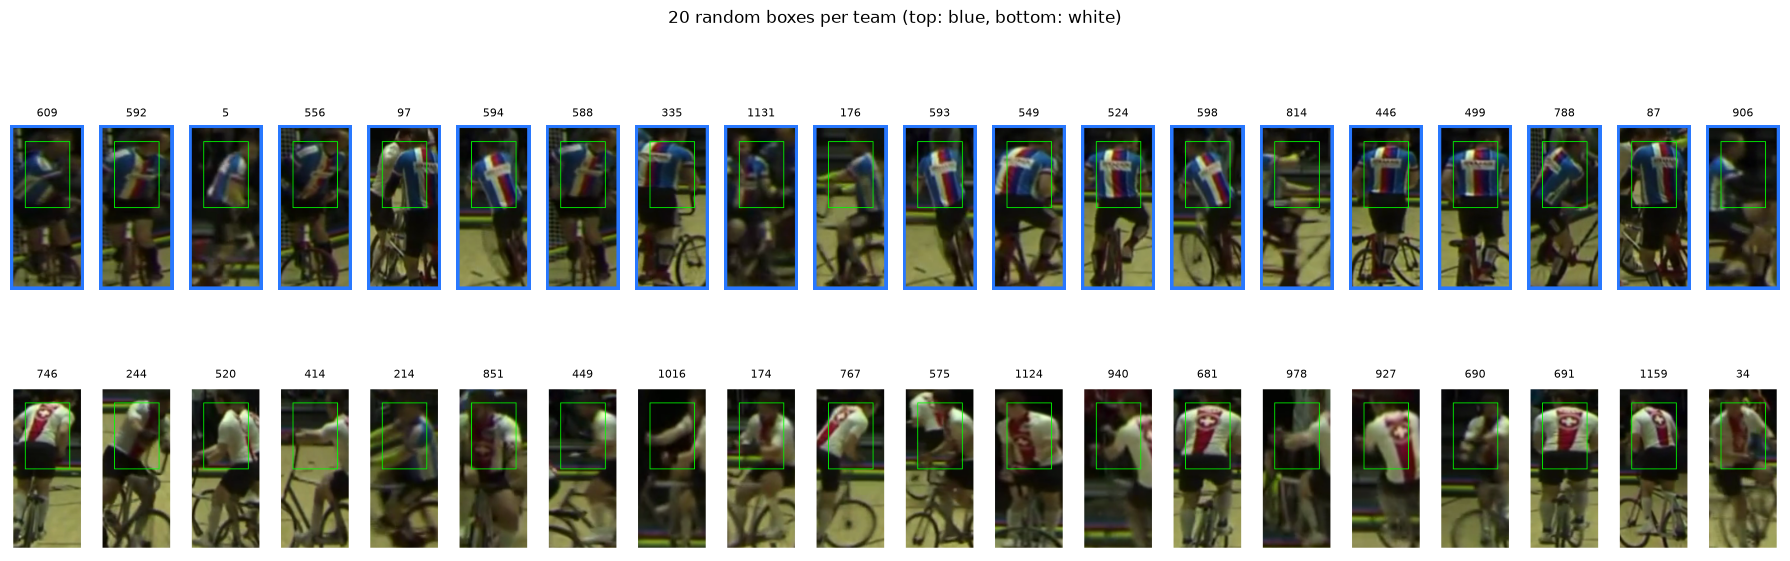

In [5]:
cluster = kmeans_two(np.sqrt(histogram))
players["team"] = np.where(cluster == shirt.blue.groupby(cluster).mean().idxmax(), "blue", "white")
display(shirt.groupby(players.team).mean().round(3))


def frame_image(number):
    video = cv2.VideoCapture(str(VIDEO))
    video.set(cv2.CAP_PROP_POS_FRAMES, number - 1)   # OpenCV counts frames from 0, we count from 1
    return video.read()[1]


size = (90, 200)
shirt_area = ((int(SHIRT_SIDE * size[0]), int(SHIRT_TOP * size[1])), (int((1 - SHIRT_SIDE) * size[0]), int(SHIRT_BOTTOM * size[1])))
fig, axes = plt.subplots(2, 20, figsize=(18, 6.5))
for row_axes, team in zip(axes, TEAM_COLOURS):
    for ax, (_, r) in zip(row_axes, players[players.team == team].sample(20, random_state=SEED).iterrows()):
        crop = cv2.resize(frame_image(r.frame)[int(r.y1):int(r.y2), int(r.x1):int(r.x2)], size)
        cv2.rectangle(crop, *shirt_area, (0, 255, 0), 1)
        cv2.rectangle(crop, (0, 0), (size[0] - 1, size[1] - 1), TEAM_COLOURS[team], 6)
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(r.frame, fontsize=8)
        ax.axis("off")
fig.suptitle("20 random boxes per team (top: blue, bottom: white)")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "team_samples.png", dpi=110)
plt.show()

**Findings:** the blue cluster's average shirt has clearly more blue and dark, the white cluster's more white and orange-yellow: those are the two kits. In the sample, 33 of the 40 crops are clearly in the right team and 6 are too dark or blurred to tell by eye (blue row: 1131, 176, 814, 906; white row: 1016, 978). One is probably wrong: frame 214 in the white row looks like a blue rider, at the darker left end of the court (see 4b).

### 4b. The frames that do not split 2 v 2

Colour mistakes or detection mistakes? We count how many of these frames contain a duplicate box, and draw one frame that splits 2 v 2 next to three that do not.

71 of 858 four-box frames do not split 2 v 2; 15 of them contain a duplicate box
the others: [50, 51, 54, 55, 56, 57, 109, 110, 111, 112, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 228, 229, 244, 245, 246, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 283, 284, 285, 629, 630, 799, 800, 801, 802, 805, 806, 955, 956, 1021, 1022, 1023, 1024, 1025, 1026, 1027]


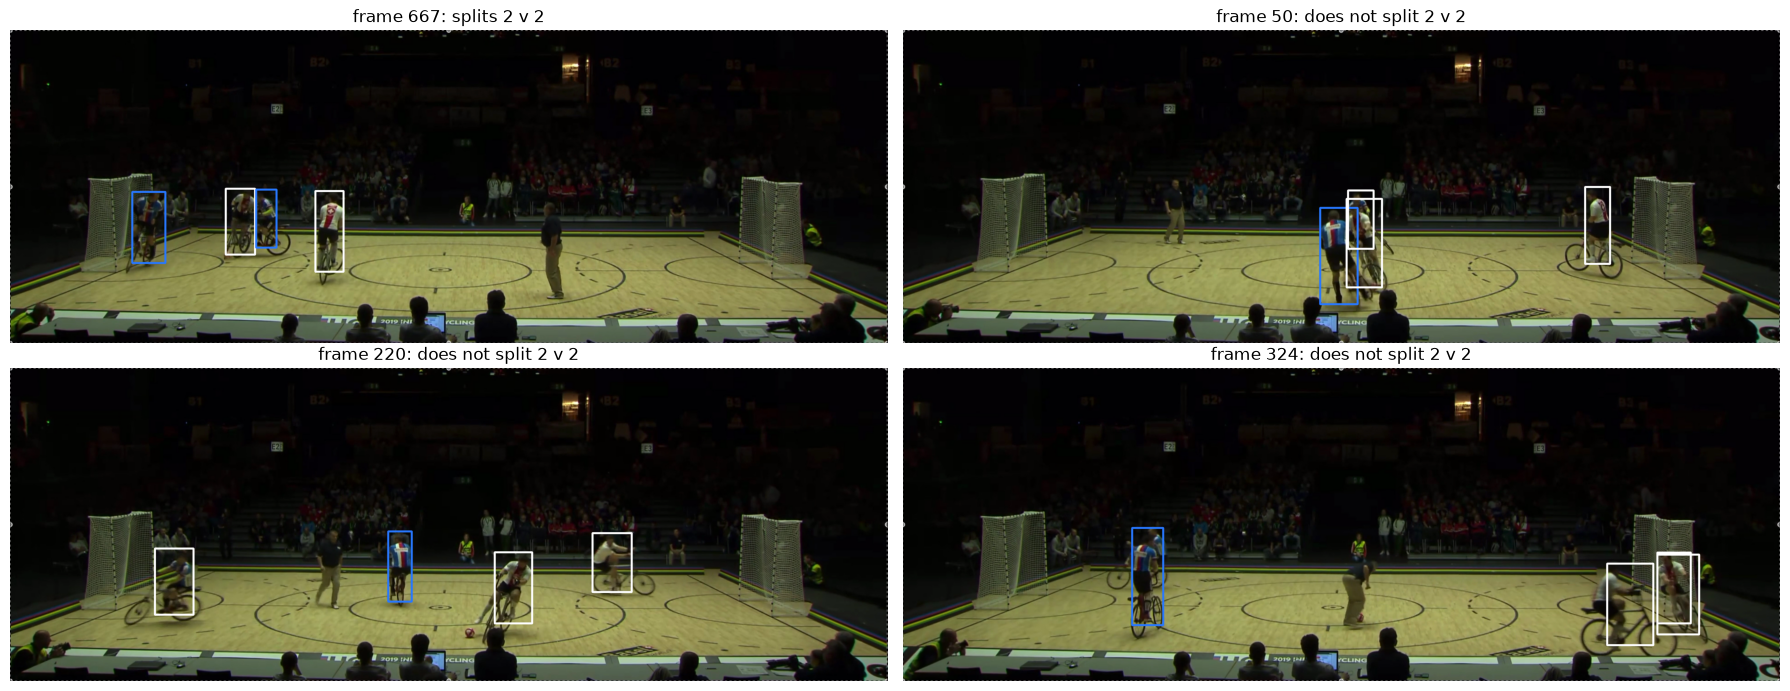

In [6]:
def draw_teams(frame):
    image = frame_image(frame)
    for _, r in players[players.frame == frame].iterrows():
        cv2.rectangle(image, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), TEAM_COLOURS[r.team], 6)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


blues = (players.team == "blue").groupby(players.frame).sum()
four = counts.index[counts == 4]
not_split = four[blues[four] != 2]
print(f"{len(not_split)} of {len(four)} four-box frames do not split 2 v 2; {duplicates[not_split].sum()} of them contain a duplicate box")
print("the others:", [f for f in not_split if not duplicates[f]])

split = four[blues[four] == 2]
examples = [split[len(split) // 2], *not_split[:: len(not_split) // 3][:3]]   # one from the middle of the clip, three spread out
fig, axes = plt.subplots(2, 2, figsize=(18, 7))
for ax, frame in zip(axes.flat, examples):
    ax.imshow(draw_teams(frame))
    ax.set_title(f"frame {frame}: {'splits 2 v 2' if frame not in not_split else 'does not split 2 v 2'}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "team_frames.png", dpi=110)
plt.show()

**Findings:** 71 of the 858 four-box frames do not split 2 v 2, and 15 of them contain a duplicate box: detection mistakes, not colour mistakes (frame 324: two boxes on one white rider, while another rider is missed). We also looked at the other 56 (printed above) by eye. They come in short runs of 2–16 frames, of three kinds:

- **A blue rider by the left goal put in the white team** (frames 214–229, 244–246, 270–285: 29 frames; frame 220 above). That end of the court is darker, and his shirt shows little blue. These are the real colour mistakes.
- **Loose double boxes:** a second, looser box on one rider, or one box over two riders close together, which the IoU 0.5 duplicate check does not catch (frames 50–57, 109–112, 629–630, 955–956: 14 frames; frame 50 above).
- **The referee inside a player box,** standing among or in front of the riders (frames 799–806 and 1021–1027: 13 frames).

**Conclusions:** only 29 of the 71 frames (two in five) are real colour mistakes, all at the dark left goal. The other 42 start in the detector: double boxes (notebook 03, hypothesis 6) and the referee (hypothesis 7). The colour mistakes last 2–16 frames, so a majority vote per rider over a longer stretch could fix them, which needs tracking (ByteTrack); the box mistakes need a better detector.

## 5. Hand-off: `models/teams.csv`

One row per player box of `detections.csv`, in the same order: `frame` (1–1170), the box `x1, y1, x2, y2` in pixels of the 3024 × 1078 frame, and `team` (`blue` or `white`). The app can join it to the detections on `frame` and the box, and colour the map dots by team.

In [7]:
players[["frame", *XY, "team"]].to_csv(OUTPUT, index=False)
print(f"{len(players)} rows written to {OUTPUT.relative_to(ROOT)}")

4669 rows written to models/teams.csv


## Limits

- **One decision per box per frame.** Without tracking, a rider can switch team for a few frames when the box is bad or the light is poor. Tracking (ByteTrack, the pipeline's Extra Mile) would allow a majority vote over all frames of one rider.
- **Two kits of similar colour** (for example both white with different trims) would be hard to separate on colour alone. The white and dark limits are general, but they were only checked on this clip.
- **Detection mistakes carry over:** a missed or doubled rider is a missed or doubled team dot, and a referee inside a player box becomes a team dot too (section 4b).